# What do AI agents actually change?
**Paper:** Dovhoshliubnyi et al. 2026 – What Do AI Agents Actually Change? (SSBSE challenge)
**Data:** https://github.com/5uper6rain/ssbse-challenge-2026

**What is in the data:** **Performance** pull requests from AIDev (AI agents and humans). The AI PRs are cut into **hunks** (small pieces of changed code) and each hunk gets a **change type** (rename, new object, type change, control flow…). ⚠️ These are changes **made by the AI**, not fixes of AI code – we use it for the **method** (how to describe a code change).

**One row of the main table =** one performance PR (table 1) · one hunk (table 2)

This notebook has 3 parts:
1. **First look** – the files, some lines, all the columns, the size.
2. **Data-science view** – size, dates, **numbers per AI agent**, **how the agent is involved** (tables saved in `tables/`).
3. **Charts** – what kind of change · fixes per AI agent · who wrote the fix · how fast the fix comes · extra (saved in `charts/`).

In [1]:
import sys, os, json
sys.path.insert(0, "..")          # to find common.py in the parent folder
from common import *

## 0. Get the data

In [2]:
root = get_repo("https://github.com/5uper6rain/ssbse-challenge-2026", "ssbse-challenge-2026")

Data folder: ../../data/06_Dovhoshliubnyi_Hunks/ssbse-challenge-2026


## 1. First look
### Files in the repository

In [3]:
list_files(root).head(20)

,file,size_MB
0,perf_improvement_parts.csv,1.68
1,data/msr_paper/performance_prs_ai_vs_human.csv,1.30


### Table 1: performance PRs (AI and human)

In [4]:
prs = pd.read_csv(os.path.join(root, "data", "msr_paper", "performance_prs_ai_vs_human.csv"))
_ = overview(prs.drop(columns=["body", "gpt_explanation", "gpt_comparison"]), "Performance PRs")

**Performance PRs** — **428 rows × 19 columns** (0.2 MB in memory)

*First 5 lines:*

,id,number,title,classification_reason,agent,author_type,state,created_at,merged_at,is_merged,time_to_merge_days,primary_language,repo_id,html_url,has_body,body_length,description_quality_score,optimization_pattern,optimization_subpattern
0,3200679276,4304,Implement lazy loading for RegistryInstance to improve l...,The PR introduces lazy loading to improve latency and re...,Claude_Code,AI Agent,closed,2025-07-03 21:18:03+00:00,2025-07-04 08:34:04+00:00,True,0.469456,Julia,82341193.0,https://github.com/JuliaLang/Pkg.jl/pull/4304,True,871.0,2,Code Smells and Structural Simplification,Remove Redundant Method Calls
1,3250477735,397,Optimize nancorrmatrix and nancovmatrix for cache locality,The changes improve the performance of the functions by ...,Claude_Code,AI Agent,closed,2025-07-22 00:19:55+00:00,2025-07-22 00:28:17+00:00,True,0.005810,Python,25501620.0,https://github.com/numbagg/numbagg/pull/397,True,676.0,2,Memory and Data Locality Optimizations,Increase Cache Efficiency via Locality
2,3254647682,59071,skip unnecessary alias-check in collect(::AbstractArray)...,The PR introduces an optimization by skipping an unneces...,Claude_Code,AI Agent,closed,2025-07-23 02:52:46+00:00,NaN,False,NaN,Julia,1644196.0,https://github.com/JuliaLang/julia/pull/59071,True,1262.0,3,Control-Flow and Branching Optimizations,Remove Branches by Doing Extra Work
3,3151002300,6671,Use async file system APIs instead of sync APIs in insta...,The PR replaces synchronous file system API calls with a...,Copilot,AI Agent,closed,2025-06-16 19:04:49+00:00,2025-06-17 20:07:52+00:00,True,1.043785,C#,323665366.0,https://github.com/microsoft/kiota/pull/6671,True,1260.0,1,I/O and Synchronization,Non-Blocking I/O
4,3151370964,12025,Add fast-paths for ToolLocationHelper property functions,The PR introduces new fast-path implementations for exis...,Copilot,AI Agent,open,2025-06-16 21:24:28+00:00,NaN,False,NaN,C#,32051890.0,https://github.com/dotnet/msbuild/pull/12025,True,3165.0,4,Algorithm-Level Optimizations,Select Computationally Efficient Algorithms


*All columns:*

,column,type,missing_%,unique,example
0,id,int64,0.0,428,3200679276
1,number,int64,0.0,403,4304
2,title,str,0.0,422,Implement lazy loading for RegistryInstance to imp
3,classification_reason,str,0.0,393,The PR introduces lazy loading to improve latency
4,agent,str,0.0,6,Claude_Code
5,author_type,str,0.0,2,AI Agent
6,state,str,0.0,2,closed
7,created_at,str,0.0,428,2025-07-03 21:18:03+00:00
8,merged_at,str,42.8,245,2025-07-04 08:34:04+00:00
9,is_merged,bool,0.0,2,True


### Table 2: the hunks of the AI PRs with their change type

In [5]:
hunks = pd.read_csv(os.path.join(root, "perf_improvement_parts.csv"))
_ = overview(hunks.drop(columns=["hunk_content", "categories_reasoning"]), "Hunks")

**Hunks** — **1,254 rows × 9 columns** (0.3 MB in memory)

*First 5 lines:*

,part_id,pr_id,pr_url,final_sub_pattern,commit_sha,filename,hunk_index,agreement_type,categories
0,1,3046430027,https://github.com/calcom/cal.com/pull/21162,Batch API Requests (N+1),NaN,packages/lib/server/repository/eventType.ts,2,partial_agree,2:comment_modification(0.95)@L4-4
1,2,3106780046,https://github.com/OpenHFT/Chronicle-Core/pull/813,Buffering,NaN,src/main/java/net/openhft/chronicle/core/io/Wget.java,5,full_agree,13:control_flow(0.95)@L5-10; 14:object_creation(0.95)@L7...
2,3,3106804055,https://github.com/OpenHFT/Chronicle-Core/pull/814,Buffering,NaN,src/main/java/net/openhft/chronicle/core/io/Wget.java,5,full_agree,15:statement_splitting(0.90)@L1-10; 13:control_flow(0.90...
3,4,3200979351,https://github.com/marin-community/marin/pull/1429,Buffering,NaN,marin/generation/sliding_logits.py,1,partial_agree,14:object_creation(0.95)@L27-47; 12:name_modification(0....
4,5,3073532077,https://github.com/ryokun6/ryos/pull/50,Caching,NaN,api/chat.ts,1,partial_agree,14:object_creation(0.95)@L4-10


*All columns:*

,column,type,missing_%,unique,example
0,part_id,int64,0.0,1254,1
1,pr_id,int64,0.0,216,3046430027
2,pr_url,str,0.0,216,https://github.com/calcom/cal.com/pull/21162
3,final_sub_pattern,str,0.0,33,Batch API Requests (N+1)
4,commit_sha,str,99.2,2,7512e8936abb569fd78d138820adaafb39ea7364
5,filename,str,0.0,550,packages/lib/server/repository/eventType.ts
6,hunk_index,int64,0.0,18,2
7,agreement_type,str,0.0,2,partial_agree
8,categories,str,0.2,714,2:comment_modification(0.95)@L4-4


## 2. Data-science view
### Size and dates

In [6]:
prs["agent"] = prs["agent"].map(lambda a: "Human" if a == "Human" else agent_of(a))
prs["created_at"] = pd.to_datetime(prs["created_at"], utc=True, errors="coerce")
hunks["types"] = hunks["categories"].astype(str).str.findall(r"\d+:([a-z_]+)\(")
print("PRs:", len(prs), "| AI:", (prs.author_type == "AI Agent").sum(), "| human:", (prs.author_type == "Human").sum(), "| repos:", prs.repo_id.nunique())
print("Hunks:", len(hunks), "| from", hunks.pr_id.nunique(), "AI PRs")
print("Dates:", prs.created_at.min().date(), "->", prs.created_at.max().date())

PRs: 428 | AI: 340 | human: 88 | repos: 135
Hunks: 1254 | from 216 AI PRs
Dates: 2025-01-03 -> 2025-07-30


### Numbers per AI agent

In [7]:
h = hunks.merge(prs[["id", "agent"]], left_on="pr_id", right_on="id", how="left")
per_agent = prs.groupby("agent").agg(PRs=("id", "size"), merged=("is_merged", "sum"), median_days_to_merge=("time_to_merge_days", "median"))
per_agent["merge_%"] = (100 * per_agent["merged"] / per_agent["PRs"]).round(1)
per_agent = per_agent.join(h.groupby("agent").agg(hunks=("part_id", "size"))).sort_values("PRs", ascending=False)
save_table(per_agent.reset_index(), "per_agent")
per_agent

,PRs,merged,median_days_to_merge,merge_%,hunks
agent,,,,,
Codex,207,141,0.000313,68.1,305.0
Human,88,57,0.094410,64.8,NaN
Devin,62,22,0.186001,35.5,534.0
Copilot,44,12,0.565162,27.3,339.0
Cursor,24,11,0.023229,45.8,72.0
Claude Code,3,2,0.237633,66.7,4.0


### How the agent is involved
The agent **opens the whole PR** (`author_type` = AI Agent); the human PRs are the comparison group.

In [8]:
inv = prs.groupby("author_type").agg(PRs=("id", "size"), merged=("is_merged", "sum"))
save_table(inv.reset_index(), "ai_vs_human")
inv

,PRs,merged
author_type,,
AI Agent,340,188
Human,88,57


In [9]:
summary_card("Dovhoshliubnyi et al. 2026", "performance PR / hunk", len(prs), prs.repo_id.nunique(), str(prs.created_at.min().date()),
             str(prs.created_at.max().date()), ", ".join(sorted(set(prs.agent) - {"Human"})), "Agent opens the PR (changes made BY the AI)", "n/a (not fixes)")

,
paper,Dovhoshliubnyi et al. 2026
unit (1 row =),performance PR / hunk
rows,428
repos,135
first date,2025-01-03
latest date,2025-07-30
agents,"Claude Code, Codex, Copilot, Cursor, Devin"
how the agent is involved,Agent opens the PR (changes made BY the AI)
fixes of AI code,n/a (not fixes)


,paper,unit (1 row =),rows,repos,first date,latest date,agents,how the agent is involved,fixes of AI code
0,Dovhoshliubnyi et al. 2026,performance PR / hunk,428,135,2025-01-03,2025-07-30,"Claude Code, Codex, Copilot, Cursor, Devin",Agent opens the PR (changes made BY the AI),n/a (not fixes)


## 3. Charts
### Chart 1 · Type of change in each hunk (the 18-type taxonomy)

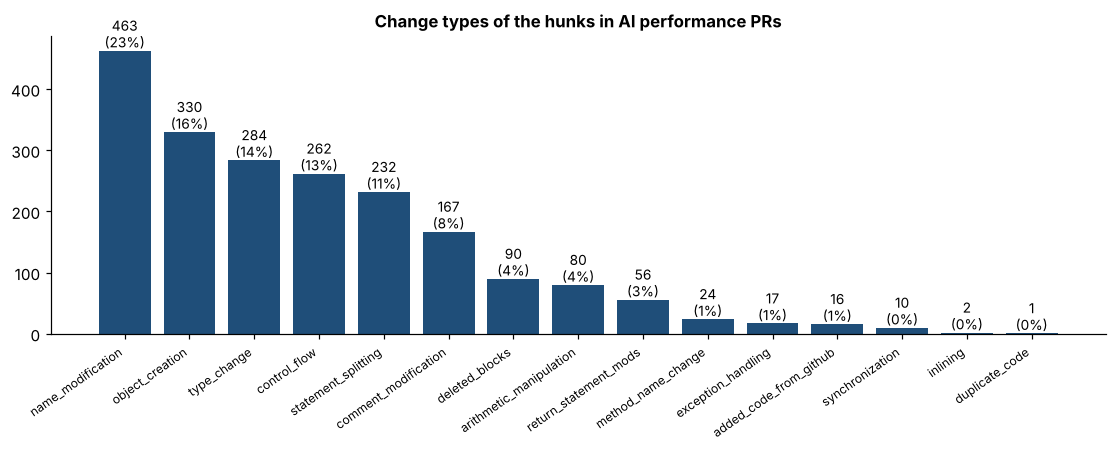

*Exact numbers – Change types of the hunks in AI performance PRs*

,number,%
types,,
name_modification,463.0,22.8
object_creation,330.0,16.2
type_change,284.0,14.0
control_flow,262.0,12.9
statement_splitting,232.0,11.4
comment_modification,167.0,8.2
deleted_blocks,90.0,4.4
arithmetic_manipulation,80.0,3.9
return_statement_mods,56.0,2.8


In [10]:
bar(hunks["types"].explode().value_counts().head(15), "Change types of the hunks in AI performance PRs", "1_hunk_types.png", horizontal=True, pct=True)

### Chart 2 · Performance PRs per AI agent (merged or not)

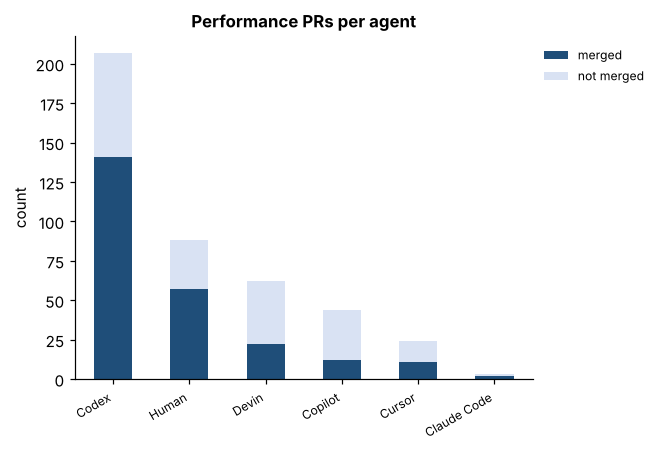

*Exact numbers – Performance PRs per agent*

is_merged,merged,not merged,TOTAL
agent,,,
Claude Code,2,1,3
Cursor,11,13,24
Copilot,12,32,44
Devin,22,40,62
Human,57,31,88
Codex,141,66,207
TOTAL,245,183,428


In [11]:
stacked(pd.crosstab(prs["agent"], prs["is_merged"].map({True: "merged", False: "not merged"})).loc[per_agent.index[::-1]], "Performance PRs per agent", "2_prs_per_agent.png", colors=[BLUE, LIGHT])

### Chart 3 · Who wrote the PR: AI agent vs human

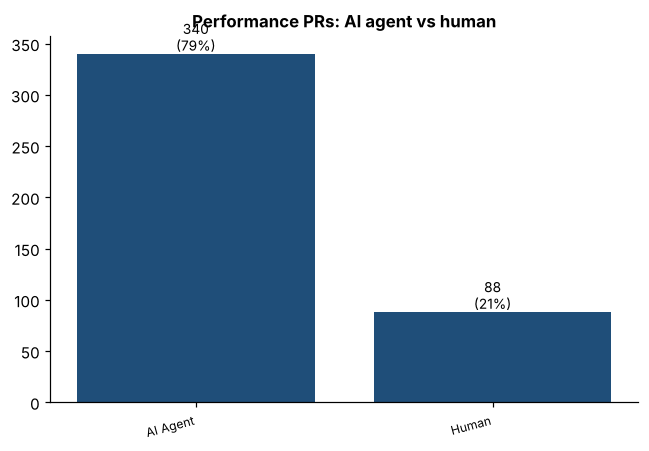

*Exact numbers – Performance PRs: AI agent vs human*

,number,%
author_type,,
AI Agent,340.0,79.4
Human,88.0,20.6
TOTAL,428.0,100.0


In [12]:
bar(prs["author_type"].value_counts(), "Performance PRs: AI agent vs human", "3_ai_vs_human.png", pct=True)

### Chart 4 · How fast the PR is merged

/tmp/ipykernel_331/2672560022.py:3: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  ax.boxplot(data, tick_labels=list(per_agent.index), vert=True); ax.set_title("Days to merge, per agent (cut at 30)"); ax.set_ylabel("days")


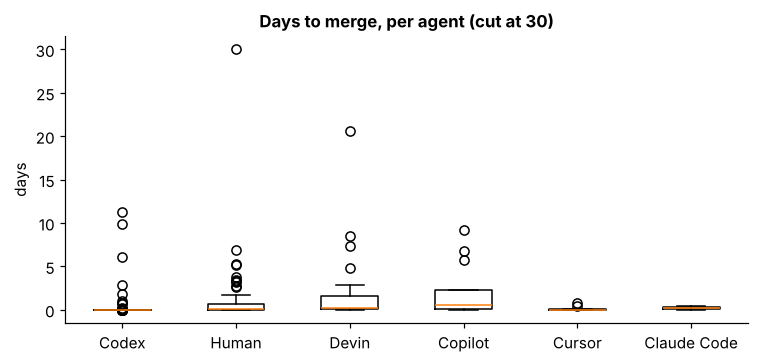

In [13]:
fig, ax = plt.subplots(figsize=(7, 3.4))
data = [prs.loc[prs.agent == a, "time_to_merge_days"].dropna().clip(upper=30) for a in per_agent.index]
ax.boxplot(data, tick_labels=list(per_agent.index), vert=True); ax.set_title("Days to merge, per agent (cut at 30)"); ax.set_ylabel("days")
save_chart(fig, "4_days_to_merge.png")

### Extra · Optimisation pattern of the PRs

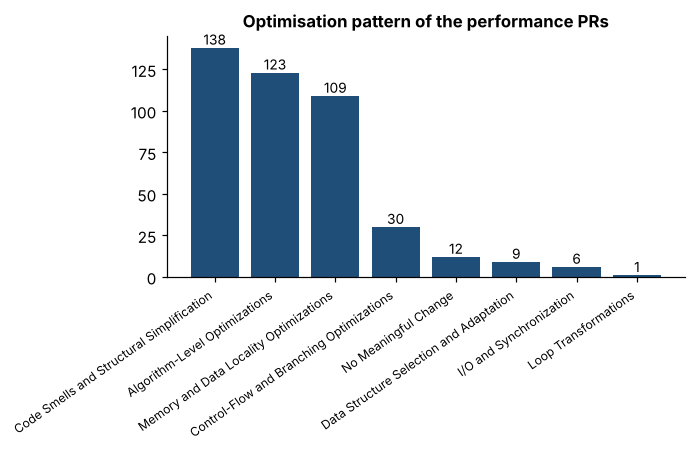

*Exact numbers – Optimisation pattern of the performance PRs*

,number,%
optimization_pattern,,
Code Smells and Structural Simplification,138.0,32.2
Algorithm-Level Optimizations,123.0,28.7
Memory and Data Locality Optimizations,109.0,25.5
Control-Flow and Branching Optimizations,30.0,7.0
No Meaningful Change,12.0,2.8
Data Structure Selection and Adaptation,9.0,2.1
I/O and Synchronization,6.0,1.4
Loop Transformations,1.0,0.2
TOTAL,428.0,100.0


In [14]:
bar(prs["optimization_pattern"].value_counts(), "Optimisation pattern of the performance PRs", "5_patterns.png", horizontal=True)

## 4. Final figure (the 4 charts on one page)

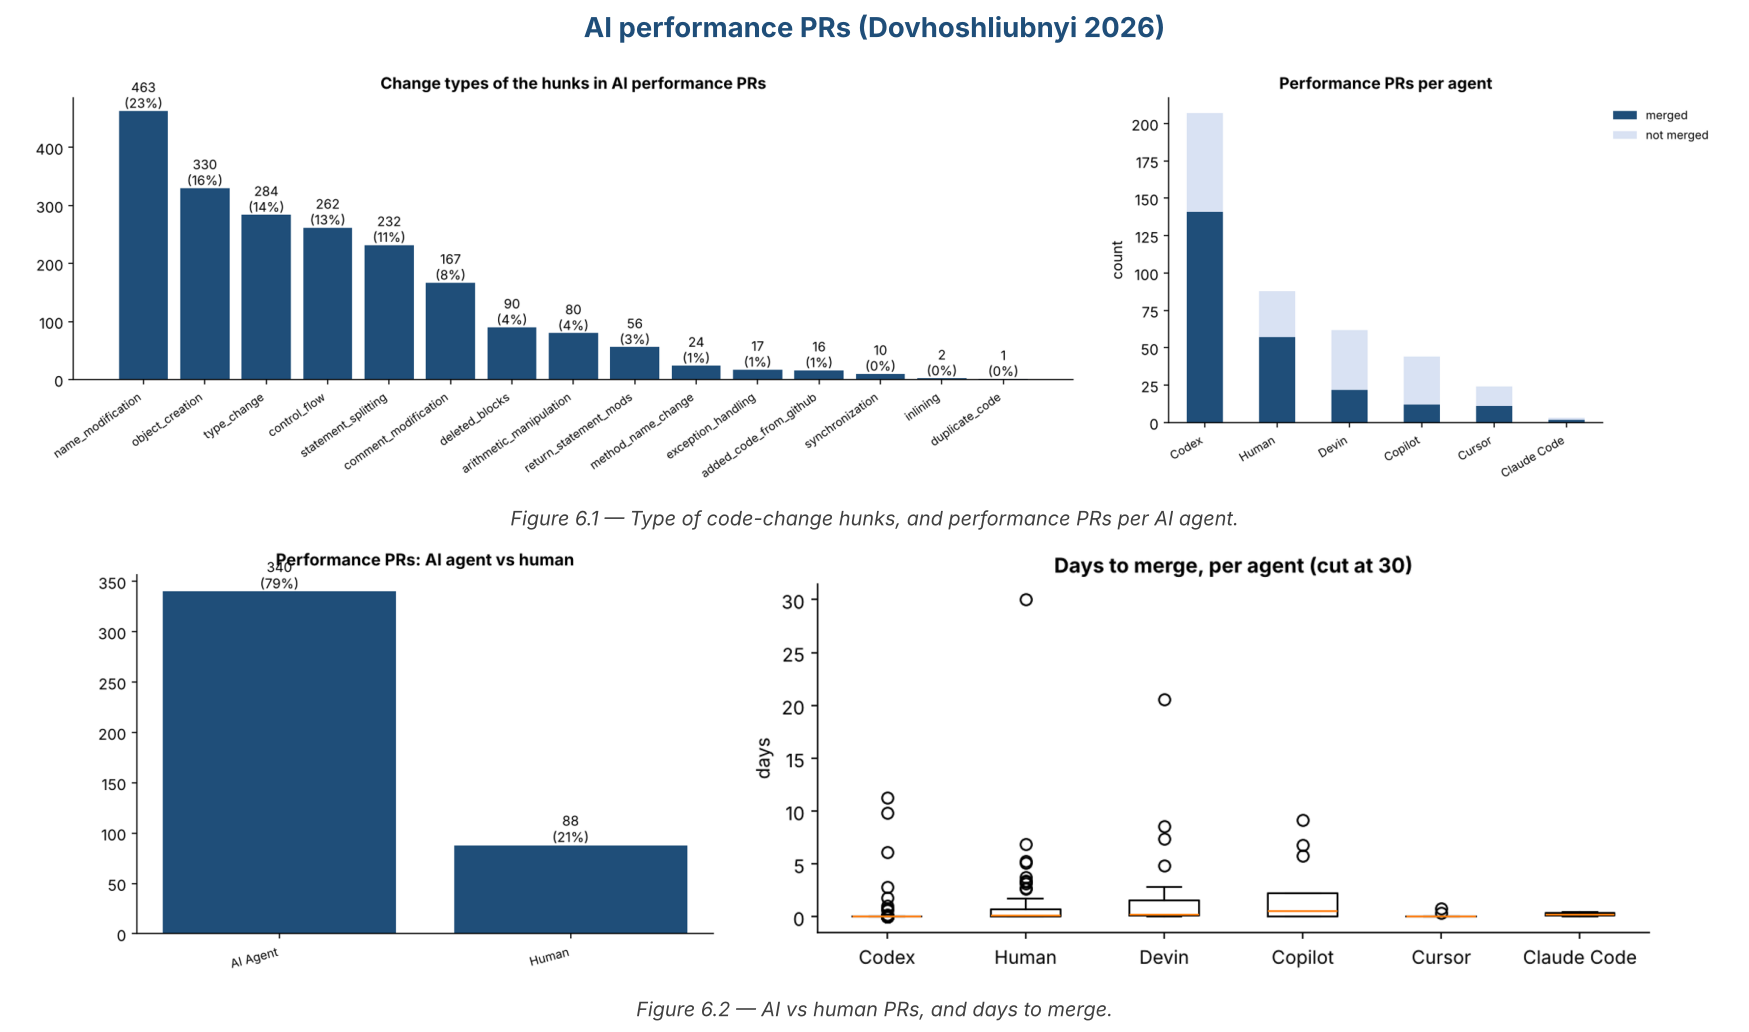

In [15]:
final_figure(6, "AI performance PRs (Dovhoshliubnyi 2026)",
             "Type of code-change hunks, and performance PRs per AI agent.",
             "AI vs human PRs, and days to merge.")

## 5. Fixes
This dataset has **no fixes of AI code** (the hunks are changes made BY the AI), so nothing is added to the final dataset.